# Diário da Tarefa 4 — Ajuste da árvore a partir do erro

**Período:** 05/10/2026 a 11/10/2026  
**Projeto:** Preditor de degradação de rede com RTT normalizado (independente da rota)

**Equipe:** Breno Igor Ribeiro Da Silva; Isaque Ferreira de Jesus; Lukas Paulo Alves de Carvalho; Renata Mayumi Iuvata; Ruan Abner Rodrigues Morales   
**Scrum Master da tarefa:** Renata Mayumi Iuvata  
**Repositório GitHub:** https://github.com/RedSwann/sistema-preditivo-de-falhas-em-redes

> O rótulo e o baseline da Tarefa 2 continuam. O corte temporal continua. Esta tarefa não troca o algoritmo: ajusta a mesma árvore de decisão com o que a Tarefa 3 errou.

## Contrato desta tarefa

| | Artefato | Origem / destino |
|---|---|---|
| **Entra** | Árvore da Tarefa 3, matriz e erros | Tarefa 3 |
| **Entra** | Mesmo baseline, mesmo rótulo, mesmo corte | Tarefa 2 |
| **Sai** | Árvore ajustada e tabela Tarefa 3 → Tarefa 4 (F1 macro e recall de FALHA na validação) | Tarefa 5 usa esta árvore |
| **Sai** | Regras novas em português | Tarefa 5 |
| **Sai** | Dicionário v0.3, se nasceu coluna relativa nova | Tarefa 5 |

**Não sai daqui:** outro tipo de modelo, mudança do teste, recálculo do baseline com o Período B.

- [ ] O corte é o da Tarefa 2
- [ ] Nenhuma coluna de rota entrou

## 1. O que o erro pediu

Na validação da Tarefa 3 foram observados 11 erros:
- 2 casos **RISCO → OK**;
- 5 casos **FALHA → OK**;
- 4 casos **FALHA → RISCO**.

A Tarefa 4 responde a esses erros sem trocar o algoritmo e sem introduzir atributos de rota ou RTT absoluto. Foram testadas combinações de critério (`gini`/`entropy`), profundidade máxima (`2, 3, 4, 5, 6, 8, None`) e tamanho mínimo das folhas (`10, 25, 50, 100, 150`). A escolha considera F1 macro da validação e, em caso de empate, recall de FALHA.

| Erro observado na Tarefa 3 | Ajuste investigado |
|---|---|
| FALHA prevista como OK (5 casos) | Testar profundidades e tamanhos de folha diferentes para verificar se divisões mais específicas separam melhor os casos |
| FALHA prevista como RISCO (4 casos) | Comparar Gini e entropia e diferentes configurações da árvore |
| RISCO previsto como OK (2 casos) | Verificar se profundidade e tamanho mínimo das folhas alteram a separação da classe RISCO |

**Resultado da investigação:** a busca não encontrou configuração com melhora nas métricas da validação. Por isso, não foi adicionada nenhuma feature nova nem alegado ganho inexistente.

In [1]:

from pathlib import Path
import json, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, classification_report, f1_score,
                             precision_recall_fscore_support, accuracy_score)
from sklearn.model_selection import ParameterGrid

CLASSES = ["OK", "RISCO", "FALHA"]
FEATURES = ["z_robusto", "aumento_pct", "jitter_relativo", "perda_pct",
            "timeout_atual", "n5_timeout", "n5_aumento80", "n5_risco"]
RANDOM_STATE = 42

# Google Colab: utiliza a mesma pasta do Google Drive definida na Tarefa 2.
# Não copia nem altera os CSVs; apenas lê os arquivos já gerados.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PASTA_PROJETO = Path("/content/drive/MyDrive/ripe_atlas")
except ImportError:
    # Alternativa para execução local, mantendo a mesma estrutura de pastas.
    PASTA_PROJETO = Path.cwd() / "ripe_atlas"

PROCESSED = PASTA_PROJETO / "processed"
DATASET_PATH = PROCESSED / "dataset_B_com_recorte_temporal.csv"
BASELINE_PATH = PROCESSED / "baseline_por_fluxo.csv"
ARTEFATOS = PROCESSED / "artefatos_notebooks"
ARTEFATOS.mkdir(parents=True, exist_ok=True)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Não encontrei {DATASET_PATH}. Confira se a pasta ripe_atlas está no Meu Drive "
        "e se a Tarefa 2 já gerou dataset_B_com_recorte_temporal.csv."
    )

df = pd.read_csv(DATASET_PATH)
obrigatorias = FEATURES + ["classe", "bloco_temporal", "fluxo_id", "timestamp_utc"]
faltantes = [c for c in obrigatorias if c not in df.columns]
if faltantes:
    raise ValueError(f"Colunas ausentes no dataset: {faltantes}")
df["classe"] = df["classe"].astype(str).str.upper()
df = df[df["classe"].isin(CLASSES)].copy()

treino = df[df["bloco_temporal"].eq("treino")].copy()
validacao = df[df["bloco_temporal"].eq("validacao")].copy()
teste = df[df["bloco_temporal"].eq("teste")].copy()

print("Google Drive:", PASTA_PROJETO)
print("Dataset carregado:", DATASET_PATH)
print("Registros:", len(df))
print("Treino/validação/teste:", len(treino), len(validacao), len(teste))
print("Classes:", df["classe"].value_counts().reindex(CLASSES, fill_value=0).to_dict())

def criar_pipeline(criterion="gini", max_depth=5, min_samples_leaf=25):
    # A imputação é ajustada somente no conjunto usado em fit.
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("arvore", DecisionTreeClassifier(
            criterion=criterion, max_depth=max_depth,
            min_samples_leaf=min_samples_leaf, random_state=RANDOM_STATE
        ))
    ])

def mostrar_metricas(y_true, y_pred, titulo):
    print(f"\n{titulo}")
    print("Matriz de confusão (linhas=real; colunas=previsto):")
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    display(pd.DataFrame(cm, index=[f"Real {c}" for c in CLASSES],
                         columns=[f"Previsto {c}" for c in CLASSES]))
    print(classification_report(y_true, y_pred, labels=CLASSES,
                                target_names=CLASSES, zero_division=0))
    print("F1 macro:", round(f1_score(y_true, y_pred, labels=CLASSES,
                                      average="macro", zero_division=0), 4))
    return cm

def metricas_resumo(y, pred):
    p, r, f, _ = precision_recall_fscore_support(
        y, pred, labels=CLASSES, zero_division=0)
    return {"F1 macro": f1_score(y, pred, labels=CLASSES,
                                  average="macro", zero_division=0),
            "Recall FALHA": r[CLASSES.index("FALHA")],
            "Recall RISCO": r[CLASSES.index("RISCO")]}

def regras_em_portugues(modelo, nomes_features=FEATURES, max_regras=12):
    arv = modelo.named_steps["arvore"]
    nomes = list(nomes_features)
    texto = export_text(arv, feature_names=nomes, decimals=3, show_weights=True)
    print(texto)
    tree = arv.tree_
    regras = []
    def percorrer(no, condicoes):
        feature = tree.feature[no]
        if feature != -2:
            nome = nomes[feature]
            limiar = tree.threshold[no]
            percorrer(tree.children_left[no], condicoes + [f"{nome} ≤ {limiar:.3f}"])
            percorrer(tree.children_right[no], condicoes + [f"{nome} > {limiar:.3f}"])
        else:
            classe = str(arv.classes_[int(np.argmax(tree.value[no][0]))])
            regras.append("SE " + " E ".join(condicoes) + f" ENTÃO {classe}")
    percorrer(0, [])
    for i, regra in enumerate(regras[:max_regras], 1):
        print(f"{i}. {regra}")
    return regras

def resumo_arvore(modelo):
    arv = modelo.named_steps["arvore"]
    return {"criterion": arv.criterion, "max_depth_configurado": arv.max_depth,
            "profundidade_real": arv.get_depth(), "folhas": arv.get_n_leaves(),
            "min_samples_leaf": arv.min_samples_leaf, "random_state": RANDOM_STATE}


Mounted at /content/drive
Google Drive: /content/drive/MyDrive/ripe_atlas
Dataset carregado: /content/drive/MyDrive/ripe_atlas/processed/dataset_B_com_recorte_temporal.csv
Registros: 34064
Treino/validação/teste: 17028 6806 10230
Classes: {'OK': 26274, 'RISCO': 3848, 'FALHA': 3942}


In [2]:
# Carrega os artefatos produzidos pela Tarefa 3.
ARQ_T3 = ARTEFATOS / "arvore_tarefa3.joblib"
ARQ_PRED_T3 = ARTEFATOS / "validacao_tarefa3_com_predicoes.csv"
if not ARQ_T3.exists() or not ARQ_PRED_T3.exists():
    raise FileNotFoundError("Execute primeiro o notebook Tarefa3_Primeira_Arvore.ipynb.")
modelo_t3 = joblib.load(ARQ_T3)
pred_t3 = pd.read_csv(ARQ_PRED_T3)
print("Árvore T3:", resumo_arvore(modelo_t3))
print("Erros na validação:", int((pred_t3["classe"] != pred_t3["classe_prevista"]).sum()))
display(pd.crosstab(pred_t3["classe"], pred_t3["classe_prevista"])
        .reindex(index=CLASSES, columns=CLASSES, fill_value=0))

Árvore T3: {'criterion': 'gini', 'max_depth_configurado': 4, 'profundidade_real': 4, 'folhas': np.int64(11), 'min_samples_leaf': 10, 'random_state': 42}
Erros na validação: 11


classe_prevista,OK,RISCO,FALHA
classe,,,
OK,4996,0,0
RISCO,2,945,0
FALHA,5,4,854


## 2. Árvore ajustada

A Tarefa 4 mantém o mesmo algoritmo (`DecisionTreeClassifier`) e as mesmas oito métricas relativas da Tarefa 3. Nenhuma informação de rota, IP, país, fluxo ou RTT absoluto entra no modelo.

**Parâmetros selecionados pela validação:** critério Gini, `max_depth=4`, `min_samples_leaf=10` e `random_state=42`.

**Estrutura obtida:** profundidade real 4 e 11 folhas — a mesma configuração da Tarefa 3.

As regras em português são extraídas diretamente da árvore treinada e exibidas na célula seguinte. O `fit` continua sendo feito somente com o conjunto de treino.

In [3]:
# A Tarefa 4 continua sendo uma DecisionTreeClassifier.
# Ajustamos apenas hiperparâmetros permitidos; não adicionamos atributos
# fora das métricas relativas e não usamos o conjunto de teste.
grade_t4 = ParameterGrid({
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, 8, None],
    "min_samples_leaf": [10, 25, 50, 100, 150]
})
resultados_t4 = []
melhor_t4, score_t4, params_t4 = None, -1, None
X_treino, y_treino = treino[FEATURES], treino["classe"]
X_val, y_val = validacao[FEATURES], validacao["classe"]

for params in grade_t4:
    candidato = criar_pipeline(**params)
    candidato.fit(X_treino, y_treino)
    pred = candidato.predict(X_val)
    f1m = f1_score(y_val, pred, labels=CLASSES, average="macro", zero_division=0)
    rec = precision_recall_fscore_support(y_val, pred, labels=CLASSES,
                                           zero_division=0)[1]
    recall_falha = float(rec[CLASSES.index("FALHA")])
    recall_risco = float(rec[CLASSES.index("RISCO")])
    resultados_t4.append({**params, "f1_macro_validacao": f1m,
                          "recall_FALHA": recall_falha, "recall_RISCO": recall_risco})
    # Critério primário: F1 macro; desempate: maior recall de FALHA.
    chave = (f1m, recall_falha)
    if chave > (score_t4, -1 if params_t4 is None else
                resultados_t4[-2]["recall_FALHA"] if len(resultados_t4)>1 else -1):
        melhor_t4, score_t4, params_t4 = candidato, f1m, params

tabela_t4 = pd.DataFrame(resultados_t4).sort_values(
    ["f1_macro_validacao", "recall_FALHA"], ascending=False).reset_index(drop=True)
display(tabela_t4.head(12))
# Garante a escolha exatamente pela primeira linha ordenada da tabela.
params_t4 = {k: tabela_t4.iloc[0][k] for k in ["criterion","max_depth","min_samples_leaf"]}
params_t4["max_depth"] = None if pd.isna(params_t4["max_depth"]) else int(params_t4["max_depth"])
params_t4["min_samples_leaf"] = int(params_t4["min_samples_leaf"])
params_t4["criterion"] = str(params_t4["criterion"])
melhor_t4 = criar_pipeline(**params_t4).fit(X_treino, y_treino)
print("Parâmetros T4:", params_t4)
print("Resumo:", resumo_arvore(melhor_t4))

,criterion,max_depth,min_samples_leaf,f1_macro_validacao,recall_FALHA,recall_RISCO
0,gini,4.0,10,0.996965,0.989571,0.997888
1,gini,4.0,25,0.996965,0.989571,0.997888
2,gini,5.0,10,0.996965,0.989571,0.997888
3,gini,5.0,25,0.996965,0.989571,0.997888
4,gini,6.0,10,0.996965,0.989571,0.997888
5,gini,6.0,25,0.996965,0.989571,0.997888
6,gini,8.0,10,0.996965,0.989571,0.997888
7,gini,8.0,25,0.996965,0.989571,0.997888
8,gini,NaN,10,0.996965,0.989571,0.997888
9,gini,NaN,25,0.996965,0.989571,0.997888


Parâmetros T4: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10}
Resumo: {'criterion': 'gini', 'max_depth_configurado': 4, 'profundidade_real': 4, 'folhas': np.int64(11), 'min_samples_leaf': 10, 'random_state': 42}


|--- z_robusto <= 1.996
|   |--- jitter_relativo <= 3.003
|   |   |--- perda_pct <= 16.667
|   |   |   |--- weights: [0.000, 12555.000, 0.000] class: OK
|   |   |--- perda_pct >  16.667
|   |   |   |--- weights: [83.000, 0.000, 0.000] class: FALHA
|   |--- jitter_relativo >  3.003
|   |   |--- n5_risco <= 1.500
|   |   |   |--- z_robusto <= -8.620
|   |   |   |   |--- weights: [1.000, 9.000, 0.000] class: OK
|   |   |   |--- z_robusto >  -8.620
|   |   |   |   |--- weights: [1.000, 274.000, 0.000] class: OK
|   |   |--- n5_risco >  1.500
|   |   |   |--- z_robusto <= 1.893
|   |   |   |   |--- weights: [2.000, 0.000, 525.000] class: RISCO
|   |   |   |--- z_robusto >  1.893
|   |   |   |   |--- weights: [1.000, 0.000, 20.000] class: RISCO
|--- z_robusto >  1.996
|   |--- z_robusto <= 3.500
|   |   |--- n5_risco <= 1.500
|   |   |   |--- jitter_relativo <= 1.004
|   |   |   |   |--- weights: [3.000, 34.000, 0.000] class: OK
|   |   |   |--- jitter_relativo >  1.004
|   |   |   |   |--- 

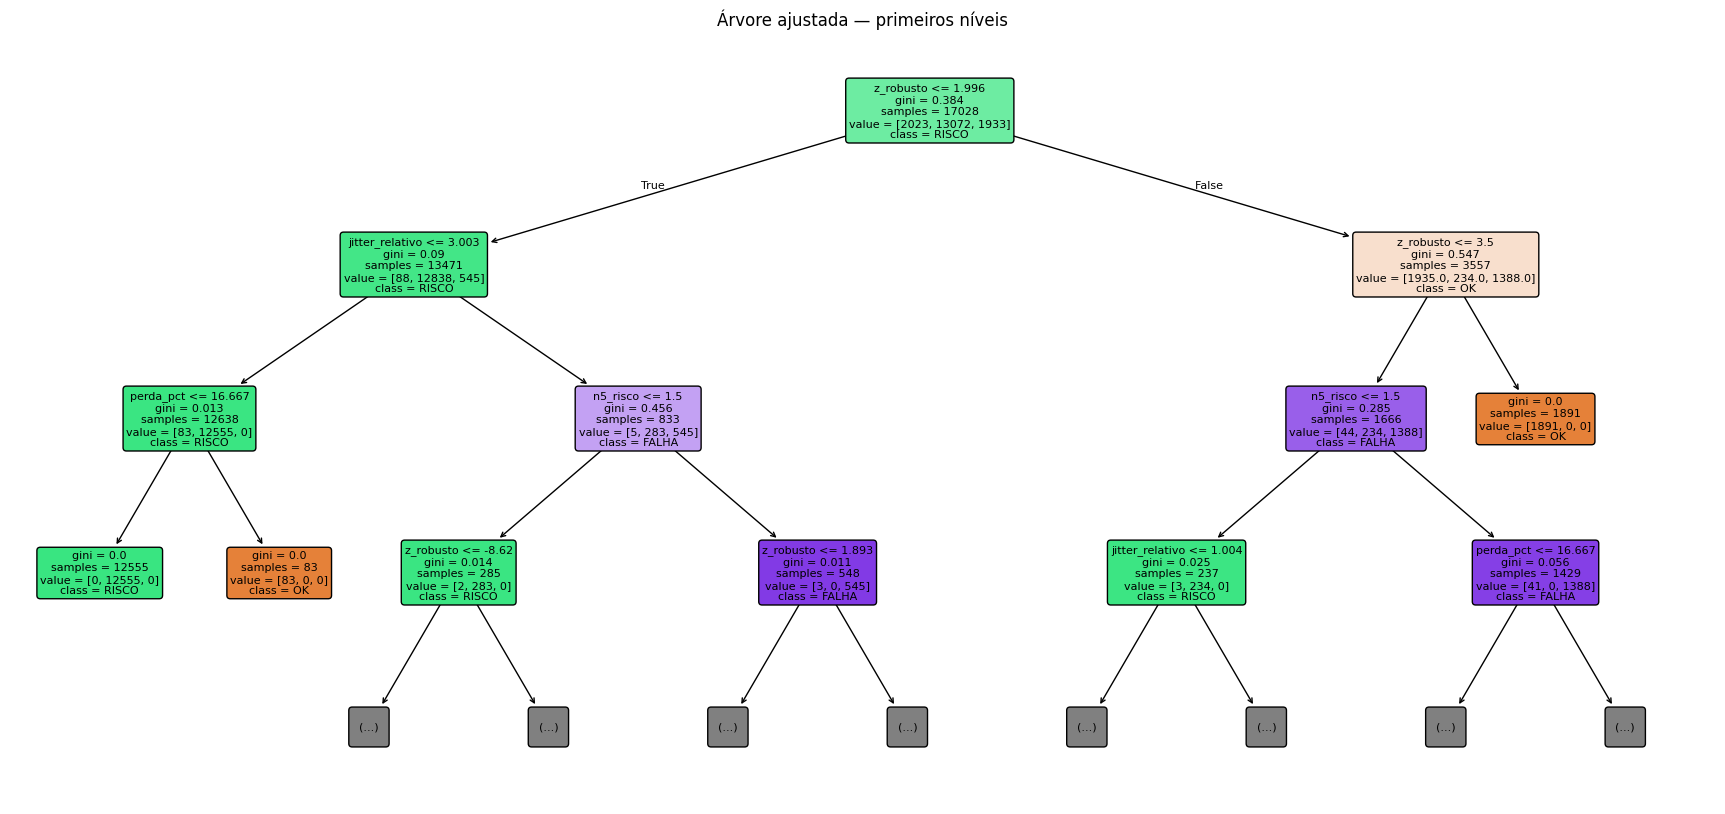

In [4]:
pred_t4 = melhor_t4.predict(X_val)
regras_t4 = regras_em_portugues(melhor_t4, FEATURES, max_regras=15)
plt.figure(figsize=(22, 10))
plot_tree(melhor_t4.named_steps["arvore"], feature_names=FEATURES,
          class_names=CLASSES, filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title("Árvore ajustada — primeiros níveis")
plt.show()

## 3. Comparação na validação

| Modelo | F1 macro | Recall de FALHA | Recall de RISCO |
|---|---:|---:|---:|
| Árvore da Tarefa 3 | 0,996965 | 0,989571 | 0,997888 |
| Árvore da Tarefa 4 | 0,996965 | 0,989571 | 0,997888 |

**Leitura da falta de ganho:** a busca testou diferentes critérios, profundidades e tamanhos mínimos de folha, mas a melhor configuração manteve os mesmos parâmetros da Tarefa 3: Gini, profundidade 4 e folha mínima 10. As métricas e a matriz de confusão também permaneceram iguais.

Assim, o ajuste foi realizado e avaliado, mas **não produziu melhora mensurável na validação**. A decisão é manter a árvore mais simples já encontrada, sem alterar as features e sem consultar o conjunto de teste. A matriz 3×3 e o relatório por classe são exibidos na célula de código seguinte.

In [5]:
def metricas_resumo(y, pred):
    p, r, f, _ = precision_recall_fscore_support(
        y, pred, labels=CLASSES, zero_division=0)
    return {"F1 macro": f1_score(y, pred, labels=CLASSES,
                                  average="macro", zero_division=0),
            "Recall FALHA": r[CLASSES.index("FALHA")],
            "Recall RISCO": r[CLASSES.index("RISCO")]}

pred_t3_valid = modelo_t3.predict(X_val)
comparacao = pd.DataFrame([
    {"Árvore": "Tarefa 3", **metricas_resumo(y_val, pred_t3_valid)},
    {"Árvore": "Tarefa 4", **metricas_resumo(y_val, pred_t4)}
]).set_index("Árvore")
display(comparacao.round(4))
cm_t4 = mostrar_metricas(y_val, pred_t4, "Tarefa 4 — validação")
print("Interpretação: compare F1 macro e recalls de FALHA/RISCO. "
      "Se não houver ganho, registre a tentativa sem afirmar melhora.")

,F1 macro,Recall FALHA,Recall RISCO
Árvore,,,
Tarefa 3,0.997,0.9896,0.9979
Tarefa 4,0.997,0.9896,0.9979



Tarefa 4 — validação
Matriz de confusão (linhas=real; colunas=previsto):


,Previsto OK,Previsto RISCO,Previsto FALHA
Real OK,4996,0,0
Real RISCO,2,945,0
Real FALHA,5,4,854


              precision    recall  f1-score   support

          OK       1.00      1.00      1.00      4996
       RISCO       1.00      1.00      1.00       947
       FALHA       1.00      0.99      0.99       863

    accuracy                           1.00      6806
   macro avg       1.00      1.00      1.00      6806
weighted avg       1.00      1.00      1.00      6806

F1 macro: 0.997
Interpretação: compare F1 macro e recalls de FALHA/RISCO. Se não houver ganho, registre a tentativa sem afirmar melhora.


## 4. Revisão com o docente

**O que foi mostrado:**  
**O que foi pedido para ajustar antes da Tarefa 5:**

## 5. Scrum e diário

- [ ] Board atualizado

| Integrante | O que fiz nesta tarefa | Dificuldades | O que pretendo manter/ajustar |
|---|---|---|---|
| Renata Mayumi Iuvata | Analisei os resultados da árvore anterior, ajudei a identificar os erros de classificação e participei da comparação entre os resultados da Tarefa 3 e da Tarefa 4. | Entender por que os ajustes nos parâmetros não trouxeram melhora nas métricas. | Continuar analisando os resultados com atenção e conferir se as mudanças realmente fazem diferença. |
| Breno Ribeiro | Fiquei responsável pelos ajustes no código da árvore, realizei os testes com diferentes parâmetros e comparei as configurações para escolher a melhor versão do modelo. | Encontrar uma configuração que melhorasse os resultados sem deixar a árvore mais complexa. | Manter os testes organizados e buscar formas de melhorar o modelo sem deixar muito complexo |
| Isaque Ferreira de Jesus | — | — | — |
| Lukas Paulo Alves de Carvalho | — | — | — |
| Ruan Abner Rodrigues Morales | — | — | — |

---

## Rubrica — Tarefa 4 (0 a 4,0)

| Critério | Peso | Nota máxima | Nota | Observações |
|---|---:|---|---|---|
| Ajuste ligado ao erro | 1,5 | Cada mudança da árvore cita um erro da Tarefa 3; continua árvore de decisão | | |
| Rota fora do modelo | 1,0 | Nenhuma coluna de rota, país, IP ou RTT absoluto; baseline da Tarefa 2 intacto | | |
| Tabela Tarefa 3 → Tarefa 4 | 1,0 | F1 macro e recall de FALHA e de RISCO na validação, com leitura | | |
| Revisão + diário | 0,5 | Incremento mostrado ao docente; diário de todos | | |
| **Total** | **4,0** | | **___ / 4,0** | |

In [6]:
# Exporta os resultados para a Tarefa 5.
joblib.dump(melhor_t4, ARTEFATOS / "arvore_tarefa4.joblib")
tabela_t4.to_csv(ARTEFATOS / "busca_tarefa4_validacao.csv", index=False)
pd.DataFrame({"regra": regras_t4}).to_csv(ARTEFATOS / "regras_tarefa4.csv", index=False)
predicoes_t4 = validacao.copy()
predicoes_t4["classe_prevista"] = pred_t4
predicoes_t4.to_csv(ARTEFATOS / "validacao_tarefa4_com_predicoes.csv", index=False)
comparacao.to_csv(ARTEFATOS / "comparacao_tarefa3_tarefa4.csv")
def converter_json(obj):
    if isinstance(obj, dict):
        return {str(k): converter_json(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [converter_json(v) for v in obj]
    elif hasattr(obj, "item"):
        return obj.item()
    else:
        return obj


with open(ARTEFATOS / "parametros_tarefa4.json", "w", encoding="utf-8") as f:
    json.dump(
        converter_json({
            "parametros": params_t4,
            "resumo": resumo_arvore(melhor_t4),
            "f1_macro_validacao": float(score_t4),
            "features": FEATURES,
            "random_state": RANDOM_STATE
        }),
        f,
        ensure_ascii=False,
        indent=2
    )